## XÂY DỰNG MÔ HÌNH HỌC MÁY DỰ BÁO BÀI HÁT THÀNH HIT (LOGISTIC REGRESSION)
- **Tệp dữ liệu đầu vào:** `data/processed/ml_tracks.csv` (~39,190 bài hát cấp Song-level độc nhất, chống rò rỉ dữ liệu)
- **Tệp đầu ra:** `models/trend_predictor.pkl`, `models/scaler.pkl`, `models/model_metrics.json`

## 1. KHỞI TẠO MÔI TRƯỜNG & THƯ VIỆN LÀM VIỆC

In [13]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Cấu hình font chữ và giao diện biểu đồ chuẩn
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

## 2. NẠP DỮ LIỆU & TIỀN XỬ LÝ ĐẶC TRƯNG ÂM HỌC (FEATURE ENGINEERING)

In [17]:
# 1. Nạp tập dữ liệu cấp bài hát
data_path='../data/processed/ml_tracks.csv'
if not os.path.exists(data_path):
    data_path='data/processed/ml_tracks.csv'

df=pd.read_csv(data_path)
print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng × {df.shape[1]} cột")

# 2. Chuyển đổi thời lượng từ mili-giây sang phút
if 'duration_min' not in df.columns and 'duration' in df.columns:
    df['duration_min']=df['duration']/60000.0

# 3. Xác định 10 đặc trưng âm học đầu vào (X)
feature_cols=[
    'danceability', 'energy', 'loudness', 'speechiness', 
    'acousticness', 'instrumentalness', 'liveness', 'valence', 
    'tempo', 'duration_min'
]

# 4. Xác định biến mục tiêu (y: is_hit)
X=df[feature_cols]
y=df['is_hit']

# Kiểm tra giá trị khuyết thiếu
print("\n Kiểm tra giá trị thiếu trong X:")
print(X.isnull().sum())

# Thống kê phân phối biến mục tiêu y
hit_counts=y.value_counts()
print("\n Phân phối nhãn mục tiêu (is_hit):")
print(f" - Nhóm 0 (Non-Hit):  {hit_counts.get(0, 0):,} bài ({hit_counts.get(0, 0)/len(y)*100:.2f}%)")
print(f" - Nhóm 1 (Top Hit):  {hit_counts.get(1, 0):,} bài ({hit_counts.get(1, 0)/len(y)*100:.2f}%)")

display(X.describe())

Kích thước dữ liệu: 39,190 dòng × 30 cột

 Kiểm tra giá trị thiếu trong X:
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_min        0
dtype: int64

 Phân phối nhãn mục tiêu (is_hit):
 - Nhóm 0 (Non-Hit):  33,727 bài (86.06%)
 - Nhóm 1 (Top Hit):  5,463 bài (13.94%)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_min
count,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000,39190.0000
mean,0.6806,0.6328,-7.0259,0.1307,0.2770,0.0161,0.1739,0.5202,121.9775,3.3407
std,0.1417,0.1677,2.7380,0.1210,0.2509,0.0953,0.1322,0.2214,28.7928,0.9292
min,0.0859,0.0032,-41.4100,0.0223,0.0000,0.0000,0.0134,0.0000,31.2620,0.5022
25%,0.5900,0.5260,-8.3910,0.0428,0.0667,0.0000,0.0963,0.3480,98.0190,2.7905
50%,0.6970,0.6450,-6.6620,0.0759,0.1990,0.0000,0.1220,0.5200,120.0705,3.2253
75%,0.7860,0.7540,-5.2270,0.1870,0.4340,0.0000,0.2070,0.6910,140.1295,3.7417
max,0.9860,1.0000,1.9060,0.9660,0.9950,0.9900,0.9900,0.9920,232.0180,29.7838


## 3. PHÂN CHIA TẬP TRAIN / TEST & CHUẨN HÓA ĐẶC TRƯNG

- **Tỷ lệ phân chia:** 80% Train – 20% Test.
- **Phân tầng (`stratify=y`):** Giữ nguyên tỷ lệ bài Hit cân đối giữa tập Train và tập Test.
- **Chuẩn hóa (`StandardScaler`):** Đưa 10 biến có thang đo khác nhau (dB, BPM, thang 0-1) về cùng trung bình $\mu = 0$ và độ lệch chuẩn $\sigma = 1$ (chỉ fit trên Train, transform trên Test).

In [18]:
# 1. Chia tập Train / Test có phân tầng
X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Chuẩn hóa đặc trưng bằng StandardScaler
scaler = StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

# Chuyển đổi ngược lại thành DataFrame để dễ quản lý tên cột
X_train_scaled_df=pd.DataFrame(X_train_scaled, columns=feature_cols)
X_test_scaled_df=pd.DataFrame(X_test_scaled, columns=feature_cols)

print(f"Kích thước tập Train: {X_train.shape[0]:,} mẫu (Tỷ lệ Hit: {y_train.mean()*100:.2f}%)")
print(f"Kích thước tập Test:  {X_test.shape[0]:,} mẫu (Tỷ lệ Hit: {y_test.mean()*100:.2f}%)")

Kích thước tập Train: 31,352 mẫu (Tỷ lệ Hit: 13.94%)
Kích thước tập Test:  7,838 mẫu (Tỷ lệ Hit: 13.94%)


## 4. HUẤN LUYỆN MÔ HÌNH HỒI QUY LOGISTIC 
- Cấu hình `class_weight='balanced'` để thuật toán tự động cân chỉnh phạt nặng hơn khi đoán nhầm lớp bài Hit (thiểu số ~13.9%), giúp tăng độ nhạy (Recall).
- Cố định `random_state=42` và `max_iter=1000`.

In [19]:
# 1. Khởi tạo mô hình
model=LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced',
    solver='lbfgs'
)

# 2. Huấn luyện mô hình trên tập Train đã chuẩn hóa
model.fit(X_train_scaled, y_train)

# 3. Dự báo nhãn phân loại và xác suất trên tập Test
y_pred=model.predict(X_test_scaled)
y_proba=model.predict_proba(X_test_scaled)[:, 1]

## 5. ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH TOÀN DIỆN

In [20]:
# 1. Tính toán các chỉ số đánh giá
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("BẢNG TỔNG HỢP HIỆU NĂNG MÔ HÌNH DỰ BÁO TOP HIT SPOTIFY")
print(f"Accuracy (Độ chính xác tổng thể):{acc*100:.2f}%")
print(f"Precision (Độ chuẩn xác lớp Hit):{prec*100:.2f}%")
print(f"Recall (Độ bao phủ lớp Hit):     {rec*100:.2f}%")
print(f"F1-Score:                        {f1:.4f}")
print(f"ROC-AUC Score:                   {roc_auc:.4f}")
print("\nCHI TIẾT CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred, target_names=['Non-Hit (0)', 'Top Hit (1)']))

BẢNG TỔNG HỢP HIỆU NĂNG MÔ HÌNH DỰ BÁO TOP HIT SPOTIFY
Accuracy (Độ chính xác tổng thể):55.19%
Precision (Độ chuẩn xác lớp Hit):17.60%
Recall (Độ bao phủ lớp Hit):     60.11%
F1-Score:                        0.2723
ROC-AUC Score:                   0.5906

CHI TIẾT CLASSIFICATION REPORT:
              precision    recall  f1-score   support

 Non-Hit (0)       0.89      0.54      0.68      6745
 Top Hit (1)       0.18      0.60      0.27      1093

    accuracy                           0.55      7838
   macro avg       0.53      0.57      0.47      7838
weighted avg       0.79      0.55      0.62      7838



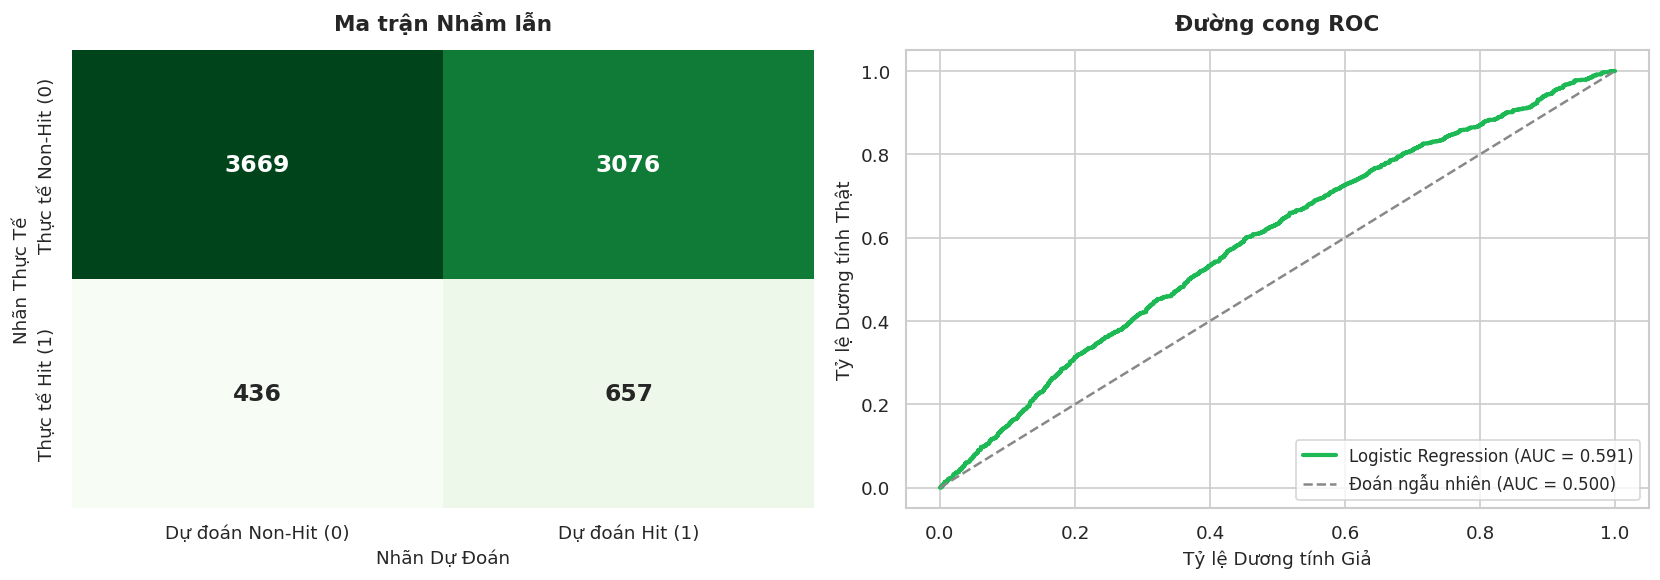

In [23]:
# 2. Vẽ biểu đồ Ma trận Nhầm lẫn và Đường cong ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#Ma trận Nhầm lẫn
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[0],
            annot_kws={"size": 14, "weight": "bold"},
            xticklabels=['Dự đoán Non-Hit (0)', 'Dự đoán Hit (1)'],
            yticklabels=['Thực tế Non-Hit (0)', 'Thực tế Hit (1)'])
axes[0].set_title("Ma trận Nhầm lẫn", fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel("Nhãn Dự Đoán", fontsize=11)
axes[0].set_ylabel("Nhãn Thực Tế", fontsize=11)

#Đường cong ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#1DB954', lw=2.5, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='#888888', linestyle='--', lw=1.5, label='Đoán ngẫu nhiên (AUC = 0.500)')
axes[1].set_xlabel("Tỷ lệ Dương tính Giả", fontsize=11)
axes[1].set_ylabel("Tỷ lệ Dương tính Thật", fontsize=11)
axes[1].set_title("Đường cong ROC", fontsize=13, fontweight='bold', pad=12)
axes[1].legend(loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

## 6. GIẢI MÃ TRỌNG SỐ & TỶ SỐ CHÊNH

- **Hệ số hồi quy $\beta$:** Thể hiện chiều hướng tác động của đặc trưng lên $\ln(\text{Odds})$.
- **Tỷ số chênh (Odds Ratio = $e^\beta$):** Khi một đặc trưng tăng thêm 1 độ lệch chuẩn, tỷ lệ cơ hội thành Hit sẽ thay đổi một lượng gấp $e^\beta$ lần (nếu $>1$ là thúc đẩy, $<1$ là kìm hãm).

BẢNG TRỌNG SỐ HỆ SỐ HỒI QUY VÀ TỶ SỐ CHÊNH
         Feature  Beta_Coefficient  Odds_Ratio  Impact_Percentage
        loudness            0.3423      1.4082            40.8190
    duration_min            0.1534      1.1658            16.5771
    acousticness            0.0872      1.0911             9.1086
    danceability            0.0827      1.0862             8.6172
         valence            0.0308      1.0313             3.1266
           tempo            0.0297      1.0301             3.0122
        liveness           -0.0167      0.9835            -1.6519
instrumentalness           -0.0227      0.9775            -2.2453
          energy           -0.1943      0.8234           -17.6570
     speechiness           -0.2038      0.8157           -18.4339


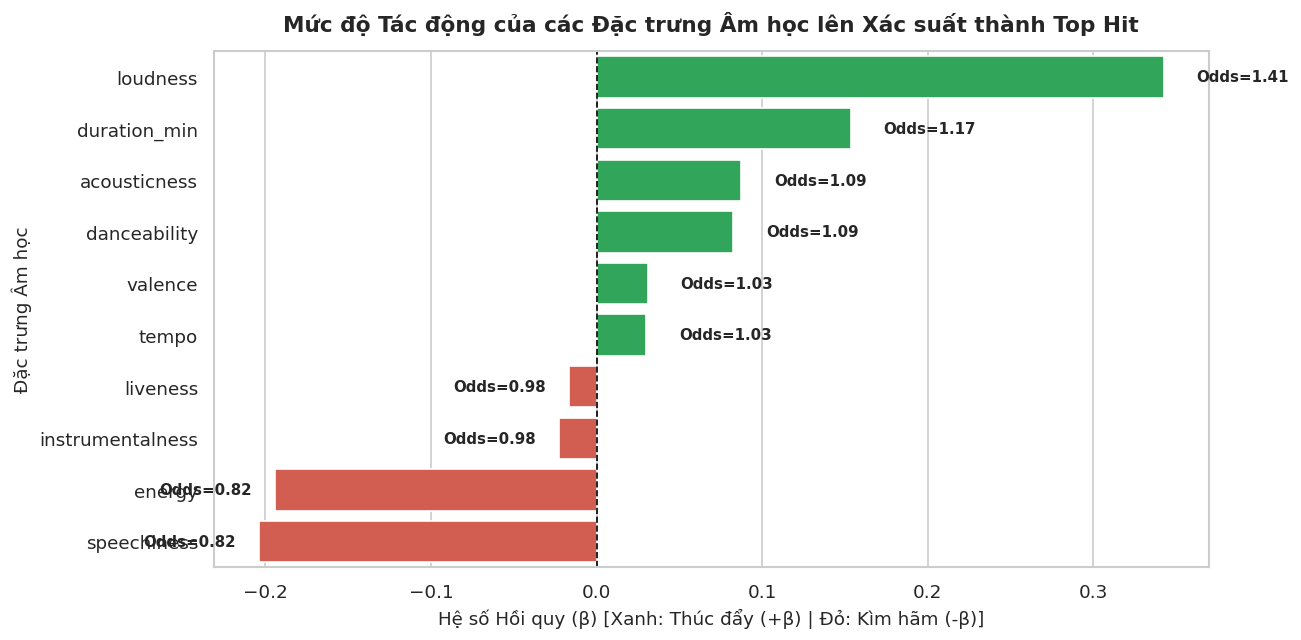

In [24]:
# 1. Xây dựng bảng trọng số và Odds Ratio
df_odds = pd.DataFrame({
    'Feature':feature_cols,
    'Beta_Coefficient':model.coef_[0],
    'Odds_Ratio':np.exp(model.coef_[0]),
    'Impact_Percentage':(np.exp(model.coef_[0]) - 1)*100
}).sort_values(by='Beta_Coefficient', ascending=False)
print("BẢNG TRỌNG SỐ HỆ SỐ HỒI QUY VÀ TỶ SỐ CHÊNH")
print(df_odds.to_string(index=False))

# 2. Trực quan hóa Biểu đồ thanh ngang tác động
plt.figure(figsize=(11, 5.5))
colors = ['#1DB954' if beta>0 else '#E74C3C' for beta in df_odds['Beta_Coefficient']]

ax = sns.barplot(data=df_odds, x='Beta_Coefficient', y='Feature', palette=colors)
plt.axvline(0, color='black', linestyle='--', lw=1)
plt.title("Mức độ Tác động của các Đặc trưng Âm học lên Xác suất thành Top Hit", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Hệ số Hồi quy (β) [Xanh: Thúc đẩy (+β) | Đỏ: Kìm hãm (-β)]", fontsize=11)
plt.ylabel("Đặc trưng Âm học", fontsize=11)

# Thêm nhãn giá trị Odds Ratio lên từng thanh
for i, row in df_odds.reset_index(drop=True).iterrows():
    val=row['Beta_Coefficient']
    odds=row['Odds_Ratio']
    offset=0.02 if val>=0 else -0.07
    ax.text(val+offset, i, f"Odds={odds:.2f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. THỬ NGHIỆM GIẢ LẬP DỰ BÁO TRỰC TIẾP

Tạo hàm mô phỏng tiếp nhận thông số một ca khúc mới và trả về xác suất thành Hit cùng lời khuyên tối ưu hóa hòa âm.

In [25]:
def simulate_track_hit(params_dict):
    """
    Hàm giả lập dự báo xác suất thành Hit của 1 bài hát mới từ 10 đặc trưng âm học.
    """
    df_input=pd.DataFrame([params_dict])[feature_cols]
    scaled_input=scaler.transform(df_input)
    prob=model.predict_proba(scaled_input)[0, 1]
    pred_label="TOP HIT" if prob>=0.50 else "NON-HIT"

    print(f"BÀI HÁT MÔ PHỎNG:{params_dict.get('name', 'Bản thu mới')}")
    print(f"Xác suất thành Top Hit:{prob*100:.2f}%")
    print(f"Phân loại dự đoán:     {pred_label}")
    
    # Khuyến nghị AI
    print("\nLời khuyên từ Mô hình:")
    if params_dict['danceability']<0.65:
        print("Độ bắt nhịp thấp. Nên tăng tiết tấu beat nhún nhảy.")
    if params_dict['loudness']<-8.0:
        print("Âm lượng nhỏ. Cần master lại âm lượng dày hơn (khoảng -6dB đến -4dB).")
    if params_dict['acousticness']>0.60:
        print("Độ mộc quá cao. Thị hiếu Top 50 chuộng âm nhạc sản xuất điện tử hiện đại.")
    if params_dict['duration_min']>4.0:
        print("Thời lượng dài. Nên rút ngắn còn 2.5-3.5 phút để tối ưu tỷ lệ nghe hết bài.")
    if prob>=0.70:
        print("Cấu trúc âm thanh rất hoàn hảo và bắt tai, tiềm năng thương mại cao!")
    print("\n")

# Thử nghiệm 2 ca khúc tiêu biểu
song_pop = {
    'name': 'Ca khúc Pop/Dance Sôi động (Ví dụ: Dua Lipa Style)',
    'danceability': 0.82,
    'energy': 0.80,
    'loudness': -4.5,
    'speechiness': 0.06,
    'acousticness': 0.08,
    'instrumentalness': 0.00,
    'liveness': 0.12,
    'valence': 0.75,
    'tempo': 124.0,
    'duration_min': 3.1
}

song_ballad = {
    'name': 'Bản Ballad Acoustic Buồn & Dài (Indie Folk)',
    'danceability': 0.38,
    'energy': 0.28,
    'loudness': -14.2,
    'speechiness': 0.03,
    'acousticness': 0.89,
    'instrumentalness': 0.05,
    'liveness': 0.10,
    'valence': 0.22,
    'tempo': 78.0,
    'duration_min': 5.6
}

simulate_track_hit(song_pop)
simulate_track_hit(song_ballad)

BÀI HÁT MÔ PHỎNG:Ca khúc Pop/Dance Sôi động (Ví dụ: Dua Lipa Style)
Xác suất thành Top Hit:55.17%
Phân loại dự đoán:     TOP HIT

Lời khuyên từ Mô hình:


BÀI HÁT MÔ PHỎNG:Bản Ballad Acoustic Buồn & Dài (Indie Folk)
Xác suất thành Top Hit:48.81%
Phân loại dự đoán:     NON-HIT

Lời khuyên từ Mô hình:
Độ bắt nhịp thấp. Nên tăng tiết tấu beat nhún nhảy.
Âm lượng nhỏ. Cần master lại âm lượng dày hơn (khoảng -6dB đến -4dB).
Độ mộc quá cao. Thị hiếu Top 50 chuộng âm nhạc sản xuất điện tử hiện đại.
Thời lượng dài. Nên rút ngắn còn 2.5-3.5 phút để tối ưu tỷ lệ nghe hết bài.




## 8. ĐÓNG GÓI & LƯU MÔ HÌNH CHO DASHBOARD STREAMLIT

Lưu 3 tệp tin phục vụ Trang 4 của Dashboard:
1. `models/trend_predictor.pkl`: Mô hình Logistic Regression đã huấn luyện.
2. `models/scaler.pkl`: Bộ chuẩn hóa StandardScaler tương ứng.
3. `models/model_metrics.json`: Bảng chỉ số đánh giá phục vụ hiển thị số liệu.

In [26]:
# Tạo thư mục models nếu chưa có
models_dir = '../models'
if not os.path.exists(models_dir):
    models_dir = 'models'
os.makedirs(models_dir, exist_ok=True)

# 1. Lưu mô hình và Scaler
model_file = os.path.join(models_dir, 'trend_predictor.pkl')
scaler_file = os.path.join(models_dir, 'scaler.pkl')
metrics_file = os.path.join(models_dir, 'model_metrics.json')

joblib.dump(model, model_file)
joblib.dump(scaler, scaler_file)

# 2. Lưu metrics dạng JSON
metrics_dict = {
    'model_name': 'Logistic Regression (Hit Predictor)',
    'accuracy': float(acc),
    'precision': float(prec),
    'recall': float(rec),
    'f1_score': float(f1),
    'roc_auc': float(roc_auc),
    'features': feature_cols,
    'coefficients': model.coef_[0].tolist(),
    'intercept': float(model.intercept_[0]),
    'train_samples': int(X_train.shape[0]),
    'test_samples': int(X_test.shape[0])
}

with open(metrics_file, 'w', encoding='utf-8') as f:
    json.dump(metrics_dict, f, indent=4, ensure_ascii=False)

print(f" 1. {model_file}")
print(f" 2. {scaler_file}")
print(f" 3. {metrics_file}")

 1. ../models\trend_predictor.pkl
 2. ../models\scaler.pkl
 3. ../models\model_metrics.json
